# POPC / water

This notebook demonstrates PDDA on water moving along the membrane-normal coordinate $z$ of a POPC bilayer. It follows local diffusivity estimation, bulk detection, interval-width selection, and validation against molecular-dynamics (MD) propagators. Distances are in Å, times in ps, and diffusivities in Å²/ps.

Residence intervals must lie inside the sampled region. The two equivalent leaflets are pooled by reflecting observations about $z=0$.

When using these analyses, cite the [original RTA paper](https://doi.org/10.1021/acs.jctc.6c00645) for diffusivity estimation and [von Domaros, Thomas, and Prabhakar (2026), arXiv:2610.29703](https://arxiv.org/abs/2610.29703) for interval selection, model comparisons, profile smoothing, and propagator calculations and validation. See the [citation guide](../README.md#citation-and-attribution) for additional method and data citations.

In [1]:
from pathlib import Path

import numpy as np
from analysis_helpers import (
    load_or_analyze_diffusivity,
    load_or_compute_propagator_comparison,
    prepare_propagator_inputs,
    regular_positions,
)
from plotting_helpers import (
    plot_bulk_convergence,
    plot_density_metrics,
    plot_diffusivity_profiles,
    plot_nll_minima,
    plot_propagator_inputs,
    plot_propagators,
)

PROJECT_ROOT = Path.cwd().resolve().parent
DATA_PATH = PROJECT_ROOT / 'data' / 'popc_water'
CACHE_PATH = PROJECT_ROOT / 'data' / 'cache' / 'popc_water'
TRAJECTORY_PATH = PROJECT_ROOT / 'data' / 'raw' / 'popc_water' / 'trajectory.z'

SAMPLING_PERIOD = 0.002  # ps
TEMPERATURE = 310.0  # K
BOX_LENGTH = 76.34  # Å
GRID_SPACING = 0.5  # Å
SMOOTHING_LENGTH = 1.0  # Å
REFERENCE_SMOOTHING_LENGTH = 2.0  # Å; VACF/PACF only
INTERVAL_WIDTHS = np.arange(GRID_SPACING, 15.0+GRID_SPACING, GRID_SPACING)  # Å
PLOT_INTERVAL_WIDTHS = (1.0, 4.0, 7.0, 10.0, 13.0)  # Å
PLATEAU_TOLERANCE = 0.05
BOUNDS = (-54.1, 54.1)  # Å

In [2]:
positions = regular_positions(BOUNDS, GRID_SPACING)
analysis = load_or_analyze_diffusivity(
    CACHE_PATH, TRAJECTORY_PATH, positions=positions,
    interval_widths=INTERVAL_WIDTHS, sampling_period=SAMPLING_PERIOD,
    bounds=BOUNDS, symmetry_center=0.0,  # Å
)
print(analysis.summary())

selection = analysis.select_profile(plateau_tolerance=PLATEAU_TOLERANCE)
nll_minima = analysis.constant_width_minima()


Diffusivity analysis: 215 positions x 30 interval widths; 6030/6450 estimates available.


## Local diffusivity profiles

The residence-time approach (RTA) estimates diffusivity for an interval of width $L$ centered at $z$:

$$\hat D_{\mathrm{RTA}}(z,L)=\frac{L^2}{12\,\hat\tau(z,L)}.$$

Here $\hat\tau$ is the mean time before a molecule exits the interval. The figure shows selected widths on the $z\geq 0$ side. Markers are estimates with approximate 95% confidence intervals (±1.96 standard errors); open markers are in the membrane, and filled markers belong to a detected bulk plateau. Positive smoothing splines use `SMOOTHING_LENGTH`. Each spline is fitted to the complete unfolded profile with reflection symmetry, which enforces zero slope at $z=0$; only its $z\geq0$ half is drawn.

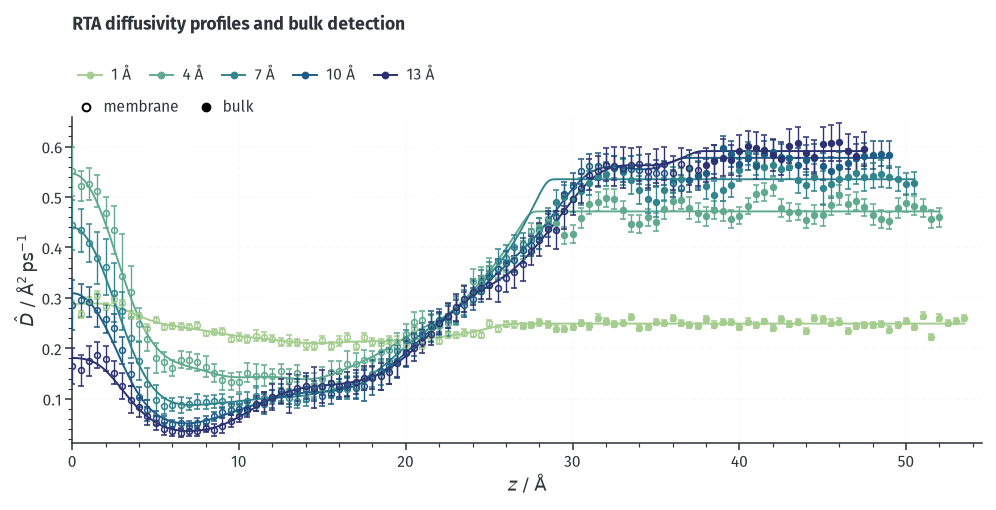

(<Figure size 980x490 with 1 Axes>,
 <Axes: title={'left': 'RTA diffusivity profiles and bulk detection'}, xlabel='$z\\ /\\ \\mathrm{\\AA}$', ylabel='$\\hat D\\ /\\ \\mathrm{\\AA}^2\\,\\mathrm{ps}^{-1}$'>)

In [3]:
plot_diffusivity_profiles(
    analysis, selection, selected_widths=PLOT_INTERVAL_WIDTHS,
    smoothing_length=SMOOTHING_LENGTH,
)

## Bulk convergence

PDDA looks for a nearly constant outer region at each interval width. It checks the outermost contiguous supported positions and requires at least two points whose relative trend and scatter meet `PLATEAU_TOLERANCE`. Across widths, it selects the highest flat run with at least four consecutive widths and at least three spatial plateau points per width.

The plot shows the bulk estimates, the selected plateau level, and its compatible width range. Larger intervals can mix bulk and membrane behavior or lose spatial support. NLL selection is restricted to the shaded range.

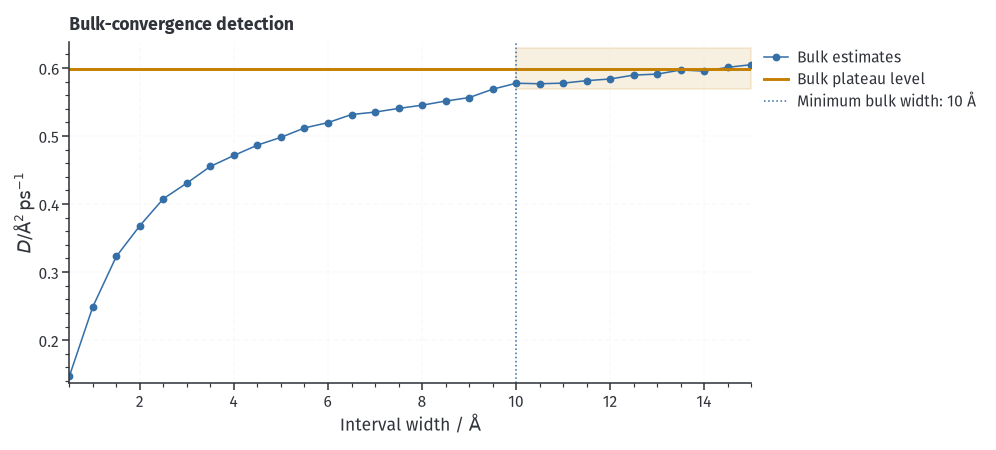

In [4]:
plot_bulk_convergence(analysis, selection)

## Select an interval width with excess NLL

Excess negative log likelihood measures how much the RTA exit-time model disagrees with the observed exit-time distribution, per observed exit:

$$\Delta\mathrm{NLL}(z,L)=\frac{\mathrm{NLL}_{\mathrm{RTA}}-\mathrm{NLL}_{\mathrm{observed}}}{N}.$$

Here $N$ is the number of observed exits; zero is the best possible value. PDDA averages the score over positions for each width; it fills gaps in the NLL map for this average only, leaving diffusivity estimates untouched. Local minima are ranked by increasing mean score. The left panel shows the NLL map and the three best minima; the right panel shows every ranked minimum. Amber highlights the lowest-scoring minimum within the bulk-compatible width range, including one ranked outside the top three.

Selected interval width 12.5 using NLL_0; profile available at 191/215 positions.
Selected interval width 11 using NLL_1; profile available at 195/215 positions.
Selected interval width 10 using NLL_2; profile available at 197/215 positions.
Selected interval width 9 using NLL_3; profile available at 199/215 positions.
Selected interval width 8 using NLL_4; profile available at 201/215 positions.
Selected interval width 7 using NLL_5; profile available at 203/215 positions.
Selected interval width 3.5 using NLL_6; profile available at 209/215 positions.
Selected NLL_0 at interval width 12.5; bulk width range 10 to 15; bulk diffusivity 0.599033.


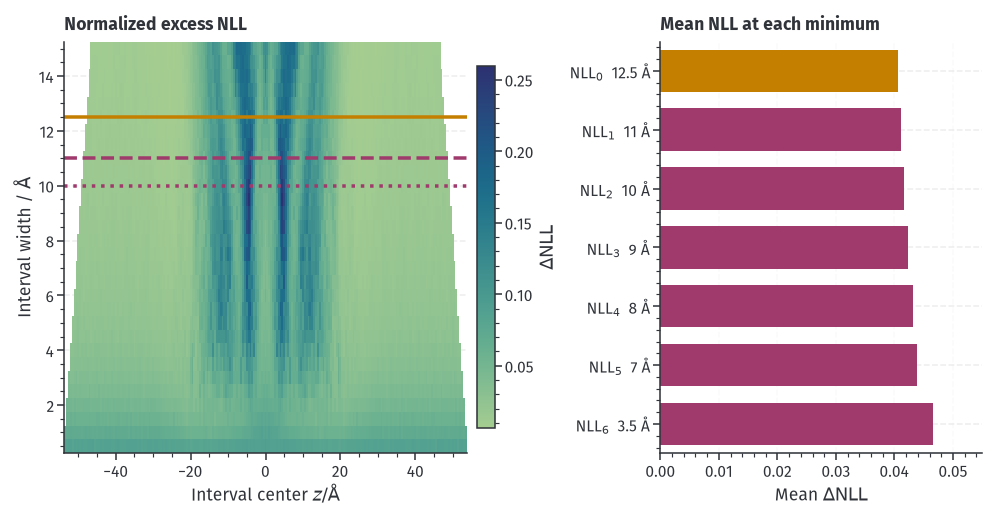

In [5]:
for candidate in nll_minima:
    print(candidate.summary())
print(selection.summary())
plot_nll_minima(analysis, nll_minima, selection)


## Validate by propagating water distributions

### Inputs

PDDA compares VACF and PACF reference diffusivities (when available) with the three best RTA minima and the selected RTA minimum (included once if already in the top three). The first panel shows the reduced potential of mean force (PMF); the second shows the fitted diffusivity profiles supplied to the propagator solver. VACF/PACF use `REFERENCE_SMOOTHING_LENGTH`; RTA profiles use `SMOOTHING_LENGTH`. These full-domain fits enforce reflection symmetry. A supported outer plateau is held constant toward the periodic boundary; an unsupported edge receives only a smooth constant extrapolation.

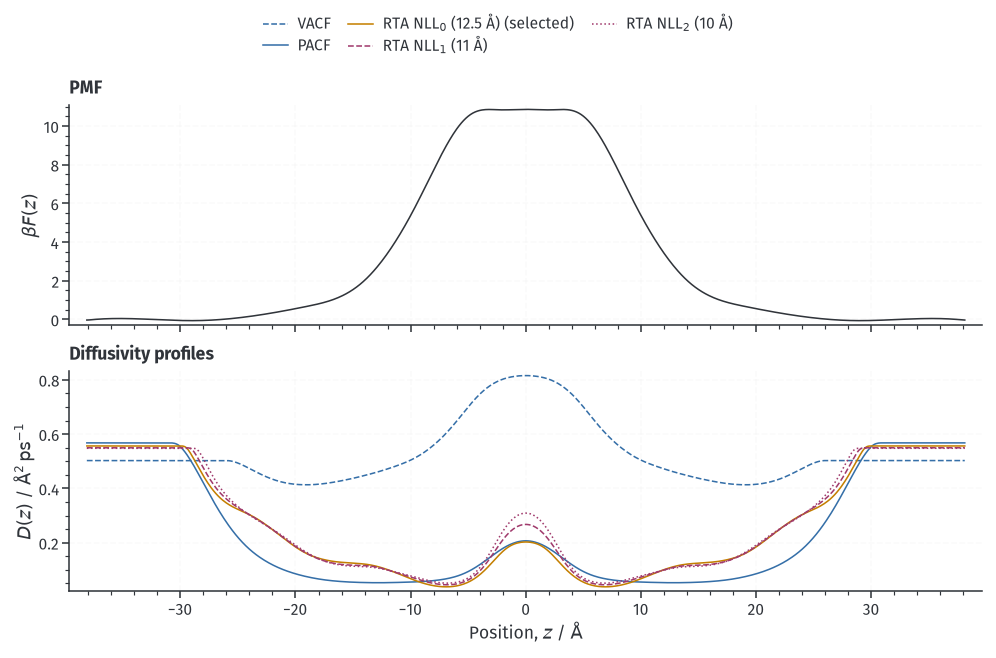

In [6]:
inputs = prepare_propagator_inputs(
    DATA_PATH, nll_minima, selection.profile,
    box_length=BOX_LENGTH, temperature=TEMPERATURE,  # Å; K
    target_spacing=0.1,  # Å
    smoothing_length=SMOOTHING_LENGTH,  # Å
    reference_smoothing_length=REFERENCE_SMOOTHING_LENGTH,  # Å
    symmetric=True,
    plateau=True, plateau_tolerance=PLATEAU_TOLERANCE, extrapolate=True,
)
plot_propagator_inputs(inputs)

### Propagators

The one-dimensional Smoluchowski equation predicts how an initially localized water distribution spreads in the same PMF. Each panel compares those predictions with the MD distribution at one lag time, on a logarithmic density scale.

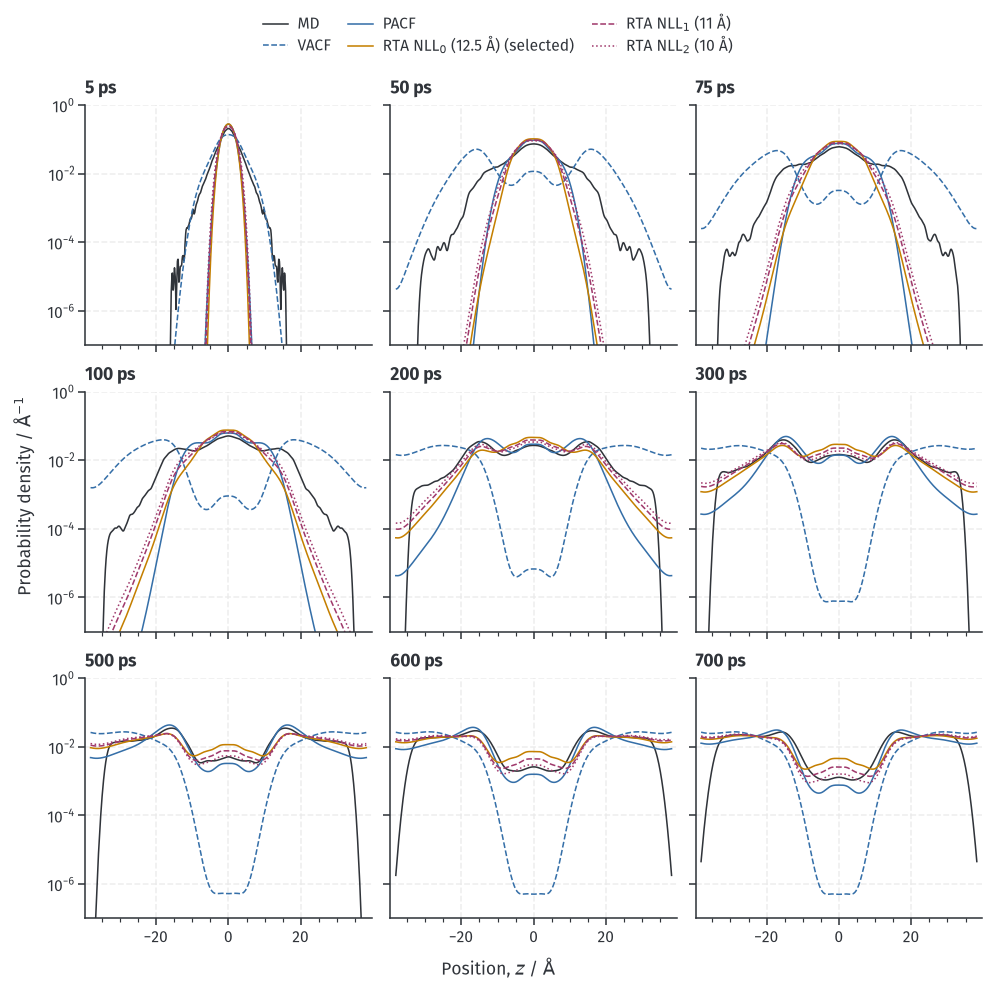

In [7]:
comparison = load_or_compute_propagator_comparison(inputs, CACHE_PATH)
plot_propagators(comparison)

### Discrepancy from MD

Six metrics summarize how each predicted distribution differs from MD across lag times. Lower values mean closer agreement for each metric; compare models within a panel because the metrics have different scales.

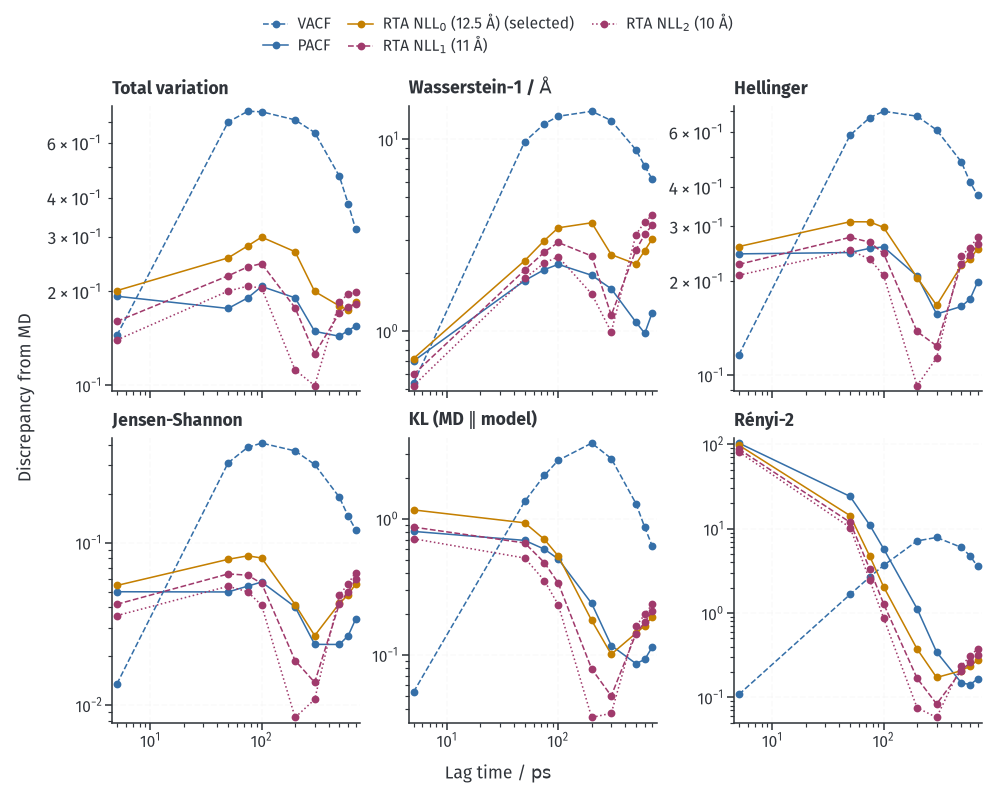

In [8]:
plot_density_metrics(comparison)